In [1]:
%pip -q install "qiskit>=1.2" "qiskit-aer>=0.15" matplotlib pandas
%pip install pylatexenc
print("Setup complete")


Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Setup complete


In [2]:
import random
import pandas as pd
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

simulator = AerSimulator()
print("Qiskit Aer simulator is ready.")


Qiskit Aer simulator is ready.


Hadamard circuit:


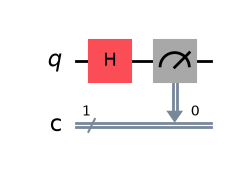

Measurement counts: {'0': 503, '1': 497}


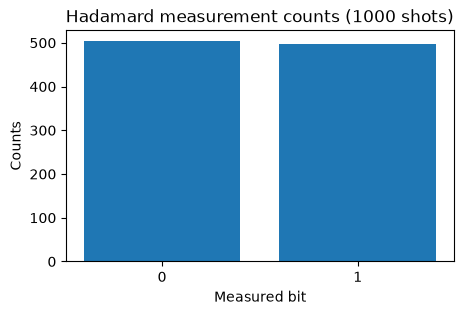

In [3]:
qc_h = QuantumCircuit(1, 1)
qc_h.h(0)
qc_h.measure(0, 0)
print("Hadamard circuit:")
display(qc_h.draw("mpl"))

counts_h = simulator.run(transpile(qc_h, simulator), shots=1000).result().get_counts()
print("Measurement counts:", counts_h)
plt.figure(figsize=(5,3))
plt.bar(["0","1"], [counts_h.get("0",0), counts_h.get("1",0)])
plt.title("Hadamard measurement counts (1000 shots)")
plt.xlabel("Measured bit"); plt.ylabel("Counts"); plt.show()


Pauli-X circuit:


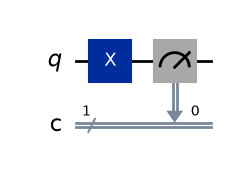

Measurement counts: {'1': 100}


In [4]:
qc_x = QuantumCircuit(1, 1)
qc_x.x(0)
qc_x.measure(0, 0)
print("Pauli-X circuit:")
display(qc_x.draw("mpl"))
counts_x = simulator.run(transpile(qc_x, simulator), shots=100).result().get_counts()
print("Measurement counts:", counts_x)


Bell-state circuit:


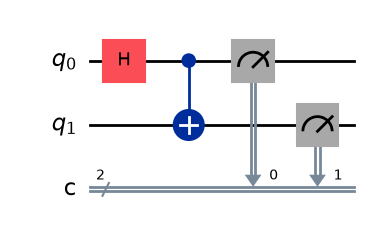

Measurement counts: {'11': 474, '00': 526}


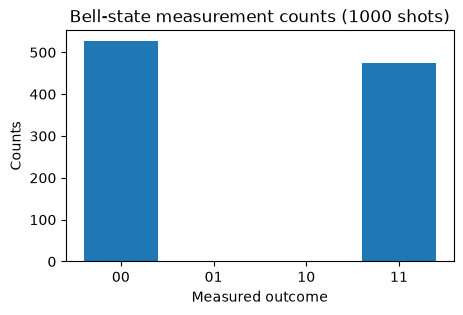

In [5]:
bell = QuantumCircuit(2, 2)
bell.h(0)
bell.cx(0, 1)
bell.measure([0,1], [0,1])
print("Bell-state circuit:")
display(bell.draw("mpl"))
counts_bell = simulator.run(transpile(bell, simulator), shots=1000).result().get_counts()
print("Measurement counts:", counts_bell)
plt.figure(figsize=(5,3))
keys = ["00","01","10","11"]
plt.bar(keys, [counts_bell.get(k,0) for k in keys])
plt.title("Bell-state measurement counts (1000 shots)")
plt.xlabel("Measured outcome"); plt.ylabel("Counts"); plt.show()


In [7]:
def measure_bb84_bit(bit, preparation_basis, measurement_basis):
    # 0 = rectilinear (+), 1 = diagonal (x)
    return bit if preparation_basis == measurement_basis else random.randint(0, 1)

def run_bb84(n_qubits=512, eve_enabled=False, eve_interception=1.0, channel_noise=0.0, seed=None):
    if seed is not None:
        random.seed(seed)
    if n_qubits < 1:
        raise ValueError("n_qubits must be positive")
    if not 0 <= eve_interception <= 1 or not 0 <= channel_noise <= 1:
        raise ValueError("Interception and noise probabilities must be between 0 and 1")

    alice_bits = [random.randint(0,1) for _ in range(n_qubits)]
    alice_bases = [random.randint(0,1) for _ in range(n_qubits)]
    bob_bases = [random.randint(0,1) for _ in range(n_qubits)]
    bob_bits, eve_flags = [], []

    for i in range(n_qubits):
        sent_bit, sent_basis = alice_bits[i], alice_bases[i]
        intercepted = eve_enabled and random.random() < eve_interception
        eve_flags.append(bool(intercepted))
        if intercepted:
            eve_basis = random.randint(0,1)
            eve_bit = measure_bb84_bit(sent_bit, sent_basis, eve_basis)
            sent_bit, sent_basis = eve_bit, eve_basis
        bob_bit = measure_bb84_bit(sent_bit, sent_basis, bob_bases[i])
        if random.random() < channel_noise:
            bob_bit = 1 - bob_bit
        bob_bits.append(bob_bit)

    sifted = [i for i in range(n_qubits) if alice_bases[i] == bob_bases[i]]
    sample_n = max(1, round(0.25 * len(sifted))) if sifted else 0
    sample = set(random.sample(sifted, sample_n)) if sample_n else set()
    errors = sum(alice_bits[i] != bob_bits[i] for i in sample)
    qber = 100 * errors / sample_n if sample_n else 0.0
    remaining = [i for i in sifted if i not in sample]

    details = [{
        "Position": i + 1,
        "Alice bit": alice_bits[i],
        "Alice basis": "+" if alice_bases[i] == 0 else "x",
        "Bob basis": "+" if bob_bases[i] == 0 else "x",
        "Bob measured bit": bob_bits[i],
        "Bases match?": alice_bases[i] == bob_bases[i],
        "Eve intercepted?": eve_flags[i],
        "Bit differs?": alice_bits[i] != bob_bits[i]
    } for i in range(n_qubits)]

    return {"n": n_qubits, "sifted": sifted, "sample_n": sample_n,
            "errors": errors, "qber": qber, "details": details,
            "candidate_match": all(alice_bits[i] == bob_bits[i] for i in remaining)}

print("BB84 simulation functions are ready.")


BB84 simulation functions are ready.



Ideal: no Eve/no noise
  Qubits transmitted: 512
  Sifted bits: 266
  QBER sample size: 66
  Sample errors: 0
  Observed QBER: 0.00%

Eve: 100% interception
  Qubits transmitted: 512
  Sifted bits: 250
  QBER sample size: 62
  Sample errors: 13
  Observed QBER: 20.97%

Eve: 50% interception
  Qubits transmitted: 512
  Sifted bits: 249
  QBER sample size: 62
  Sample errors: 10
  Observed QBER: 16.13%

Noise: 5%, no Eve
  Qubits transmitted: 512
  Sifted bits: 258
  QBER sample size: 64
  Sample errors: 4
  Observed QBER: 6.25%

Noise: 15%, no Eve
  Qubits transmitted: 512
  Sifted bits: 269
  QBER sample size: 67
  Sample errors: 13
  Observed QBER: 19.40%


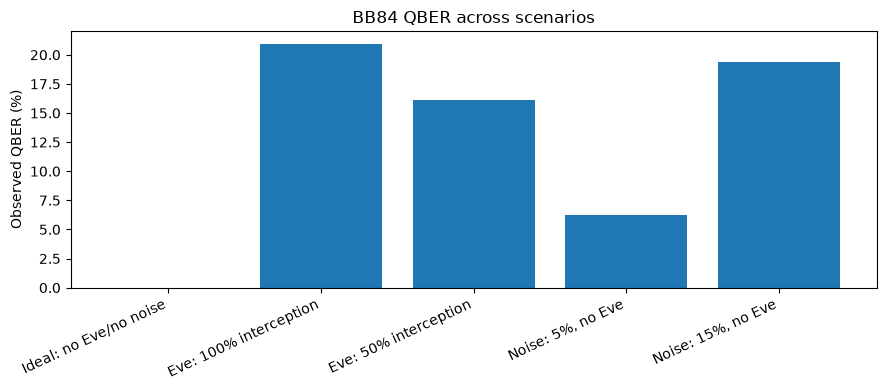

In [8]:
N = 512
scenarios = [
    ("Ideal: no Eve/no noise", False, 0.0, 0.0),
    ("Eve: 100% interception", True, 1.0, 0.0),
    ("Eve: 50% interception", True, 0.5, 0.0),
    ("Noise: 5%, no Eve", False, 0.0, 0.05),
    ("Noise: 15%, no Eve", False, 0.0, 0.15),
]
results = []
for label, eve, interception, noise in scenarios:
    r = run_bb84(N, eve, interception, noise)
    results.append((label, r))
    print(f"\n{label}")
    print(f"  Qubits transmitted: {r['n']}")
    print(f"  Sifted bits: {len(r['sifted'])}")
    print(f"  QBER sample size: {r['sample_n']}")
    print(f"  Sample errors: {r['errors']}")
    print(f"  Observed QBER: {r['qber']:.2f}%")

plt.figure(figsize=(9,4))
plt.bar(range(len(results)), [r["qber"] for _,r in results])
plt.xticks(range(len(results)), [label for label,_ in results], rotation=25, ha="right")
plt.ylabel("Observed QBER (%)")
plt.title("BB84 QBER across scenarios")
plt.tight_layout()
plt.show()


In [9]:
inspection = run_bb84(n_qubits=64, eve_enabled=True, eve_interception=1.0, channel_noise=0.0)
display(pd.DataFrame(inspection["details"]).head(20))
print(f"Sifted bits: {len(inspection['sifted'])} / {inspection['n']}")
print(f"QBER sample size: {inspection['sample_n']}")
print(f"Sample errors: {inspection['errors']}")
print(f"Observed QBER: {inspection['qber']:.2f}%")


,Position,Alice bit,Alice basis,Bob basis,Bob measured bit,Bases match?,Eve intercepted?,Bit differs?
0,1,1,+,+,0,True,True,True
1,2,1,+,x,0,False,True,True
2,3,0,+,+,0,True,True,False
3,4,0,+,+,1,True,True,True
4,5,0,x,x,1,True,True,True
5,6,0,x,x,1,True,True,True
6,7,0,+,x,0,False,True,False
7,8,0,+,x,0,False,True,False
8,9,0,x,x,0,True,True,False
9,10,1,x,+,0,False,True,True


Sifted bits: 29 / 64
QBER sample size: 7
Sample errors: 4
Observed QBER: 57.14%
